# Harmonic analysis of the mean seasonal cycle

Same 12-, 6- and 4-month harmonic regression as `../harmonic.ipynb`, but applied to the
stacked 12-month climatology `mean_seasonal_cycle.nc` (Jan–Dec) instead of the 276-month
detrended record. Phases are **not** rescaled to a 12-month calendar: each harmonic's phase
is in its own degrees (360° = one full period of that harmonic).

In [1]:
import os
import itertools
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature

IN_NC   = "mean_seasonal_cycle.nc"          # or "mean_seasonal_cycle_detrended.nc"
OUT_DIR = "../../Figures/climatology/harmonic"
os.makedirs(OUT_DIR, exist_ok=True)

cycle  = xr.open_dataarray(IN_NC).load()
mnames = list(cycle["month_name"].values)
cycle

<xarray.DataArray 'co_mmr_midtrop' (month: 12, lat: 36, lon: 61)> Size: 211kB
array([[[8.54975811e-08, 8.51977179e-08, 8.50447847e-08, ...,
         8.35957588e-08, 8.36861896e-08, 8.37892041e-08],
        [8.60178081e-08, 8.59399625e-08, 8.54771780e-08, ...,
         8.34251955e-08, 8.34157842e-08, 8.35325912e-08],
        [8.67035047e-08, 8.65309487e-08, 8.59941862e-08, ...,
         8.34343192e-08, 8.33395303e-08, 8.34259465e-08],
        ...,
        [9.84392851e-08, 9.86240129e-08, 9.78514525e-08, ...,
         8.69264937e-08, 8.69478739e-08, 8.77479741e-08],
        [9.86252536e-08, 9.83360893e-08, 9.65515019e-08, ...,
         8.85850107e-08, 8.73833140e-08, 8.73570464e-08],
        [9.77288369e-08, 9.57559470e-08, 9.59781044e-08, ...,
         8.70764608e-08, 8.86072649e-08, 9.06617606e-08]],

       [[8.40604751e-08, 8.37875429e-08, 8.37761007e-08, ...,
         8.42500519e-08, 8.42670685e-08, 8.43002511e-08],
        [8.46322355e-08, 8.45275726e-08, 8.40666787e-08, ...,
         8.38053908e-08, 8.38170613e-08, 8.38338953e-08],
        [8.51522904e-08, 8.49222361e-08, 8.46719023e-08, ...,
         8.34648138e-08, 8.34423801e-08, 8.35084757e-08],
...
         8.54988910e-08, 8.50612384e-08, 8.53213730e-08],
        [9.24778238e-08, 9.24934783e-08, 9.07891696e-08, ...,
         8.71174088e-08, 8.60358806e-08, 8.55183181e-08],
        [9.18775484e-08, 9.04060588e-08, 9.05492792e-08, ...,
         8.67713732e-08, 8.72075102e-08, 8.79944298e-08]],

       [[8.20530683e-08, 8.18776912e-08, 8.17810231e-08, ...,
         8.17524528e-08, 8.18669765e-08, 8.20357554e-08],
        [8.25208501e-08, 8.24127734e-08, 8.22018133e-08, ...,
         8.14806692e-08, 8.15594987e-08, 8.16860285e-08],
        [8.30484027e-08, 8.28488678e-08, 8.27923305e-08, ...,
         8.14074280e-08, 8.14305204e-08, 8.15733188e-08],
        ...,
        [9.45401710e-08, 9.46052573e-08, 9.33044272e-08, ...,
         8.52580130e-08, 8.50148470e-08, 8.55020174e-08],
        [9.46829098e-08, 9.45139236e-08, 9.24742393e-08, ...,
         8.68368621e-08, 8.57042666e-08, 8.53942175e-08],
        [9.33725414e-08, 9.15826027e-08, 9.14369053e-08, ...,
         8.60310983e-08, 8.71978360e-08, 8.85827886e-08]]],
      shape=(12, 36, 61))
Coordinates:
  * month       (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * lat         (lat) float32 144B 14.5 15.5 16.5 17.5 ... 46.5 47.5 48.5 49.5
  * lon         (lon) float32 244B -126.5 -125.5 -124.5 ... -68.5 -67.5 -66.5
    month_name  (month) <U3 144B 'Jan' 'Feb' 'Mar' 'Apr' ... 'Oct' 'Nov' 'Dec'
Attributes:
    long_name:  Mean seasonal cycle of AIRS CO mid-troposphere MMR (complete ...
    units:      kg kg-1
    source:     complete_data.nc
    period:     2003-01 to 2025-12
    method:     per-pixel average of all years for each calendar month

In [2]:
print("Shape     :", cycle.shape)
print("Dims      :", cycle.dims)
print("Month     :", cycle.month.values)
print("Lat       :", float(cycle.lat.min()), "->", float(cycle.lat.max()), f"  ({len(cycle.lat)} pts)")
print("Lon       :", float(cycle.lon.min()), "->", float(cycle.lon.max()), f"  ({len(cycle.lon)} pts)")
print("Min / Max :", np.nanmin(cycle.values), "/", np.nanmax(cycle.values))
print("NaNs      :", int(np.isnan(cycle.values).sum()))

Shape     : (12, 36, 61)
Dims      : ('month', 'lat', 'lon')
Month     : [ 1  2  3  4  5  6  7  8  9 10 11 12]
Lat       : 14.5 -> 49.5   (36 pts)
Lon       : -126.5 -> -66.5   (61 pts)
Min / Max : 7.351446415866478e-08 / 1.2301915513321743e-07
NaNs      : 0


## Harmonic analysis : 12 months, 6 months and 4 months harmonics

At every grid point the 12-month seasonal cycle is modelled as its annual mean plus a
superposition of annual, semi-annual and terannual waves, each built from a cosine/sine pair
$a\cos(\omega t) + b\sin(\omega t)$ with $\omega = 2\pi/P$ and $t = 0$ in January
($t = 0, 1, \dots, 11$). A least-squares fit gives $a$ and $b$ at each pixel, which are
rewritten in the cosine convention $A\cos(\omega t - \phi)$ with amplitude
$A = \sqrt{a^2 + b^2}$ and phase $\phi = \arctan(b/a)$. A positive $\phi$ means the peak occurs
later than $t = 0$.

The phases are left unscaled: for period $P$, the peak falls $\phi/360 \times P$ months after
January (and repeats every $P$ months).

Because there are exactly 12 equally spaced months, the cosines and sines are orthogonal to
each other and to the constant term, so the fitted $a$ and $b$ are the same with or without the
mean column. The mean column is included so the reconstruction and residual are complete.

In [3]:
months = cycle.month.values                # 1..12
n_t    = len(months)
n_lat  = len(cycle.lat)
n_lon  = len(cycle.lon)
lats   = cycle.lat.values
lons   = cycle.lon.values

# Setup and design matrix for harmonic regression
periods = [12, 6, 4]
t = np.arange(n_t)                         # 0 = Jan, ..., 11 = Dec
print(f"Time vector t: {t} with shape {t.shape}")

cols = []
for P in periods:
    w = 2 * np.pi / P
    cols += [np.cos(w * t), np.sin(w * t)]
cols.append(np.ones(n_t))                  # annual-mean (constant) term, last column

# M: (12, 2*len(periods) + 1)
M = np.column_stack(cols)
print(f"Design matrix M shape: {M.shape}  (month x [cos12, sin12, cos6, sin6, cos4, sin4, const])")
print(np.round(M, 3))

# Flatten spatial dims and solve least-squares at every pixel at once
Yd   = cycle.values.reshape(n_t, -1)
coef, *_ = np.linalg.lstsq(M, Yd, rcond=None)
annual_mean = coef[-1].reshape(n_lat, n_lon)

Time vector t: [ 0  1  2  3  4  5  6  7  8  9 10 11] with shape (12,)
Design matrix M shape: (12, 7)  (month x [cos12, sin12, cos6, sin6, cos4, sin4, const])
[[ 1.     0.     1.     0.     1.     0.     1.   ]
 [ 0.866  0.5    0.5    0.866  0.     1.     1.   ]
 [ 0.5    0.866 -0.5    0.866 -1.     0.     1.   ]
 [ 0.     1.    -1.     0.    -0.    -1.     1.   ]
 [-0.5    0.866 -0.5   -0.866  1.    -0.     1.   ]
 [-0.866  0.5    0.5   -0.866  0.     1.     1.   ]
 [-1.     0.     1.    -0.    -1.     0.     1.   ]
 [-0.866 -0.5    0.5    0.866 -0.    -1.     1.   ]
 [-0.5   -0.866 -0.5    0.866  1.    -0.     1.   ]
 [-0.    -1.    -1.     0.     0.     1.     1.   ]
 [ 0.5   -0.866 -0.5   -0.866 -1.     0.     1.   ]
 [ 0.866 -0.5    0.5   -0.866 -0.    -1.     1.   ]]


In [4]:
amp, pha = {}, {}

for k, P in enumerate(periods):
    # a -> cosine coefficient, b -> sine coefficient
    a_k = coef[2*k    ].reshape(n_lat, n_lon)
    b_k = coef[2*k + 1].reshape(n_lat, n_lon)

    amp[P] = np.sqrt(a_k**2 + b_k**2)

    # Phase for A*cos(wt - phi):  phi = arctan2(b, a), mapped to 0..360 degrees
    pha_rad = np.arctan2(b_k, a_k)
    pha_rad = np.where(pha_rad < 0, pha_rad + 2 * np.pi, pha_rad)
    pha[P]  = np.rad2deg(pha_rad)

    print(f"{P:2d}: amp {np.nanmin(amp[P]):.2e} - {np.nanmax(amp[P]):.2e} kg/kg, "
          f"pha {np.nanmin(pha[P]):6.2f} - {np.nanmax(pha[P]):6.2f} deg  "
          f"(peak {np.nanmin(pha[P]) * P / 360:.2f} - {np.nanmax(pha[P]) * P / 360:.2f} months after Jan)")

12: amp 3.59e-09 - 1.80e-08 kg/kg, pha  52.97 - 139.91 deg  (peak 1.77 - 4.66 months after Jan)
 6: amp 1.06e-09 - 7.49e-09 kg/kg, pha  94.75 - 224.22 deg  (peak 1.58 - 3.74 months after Jan)
 4: amp 8.92e-10 - 5.54e-09 kg/kg, pha 234.95 - 356.21 deg  (peak 2.61 - 3.96 months after Jan)


### Amplitude and phase maps (phase unscaled)

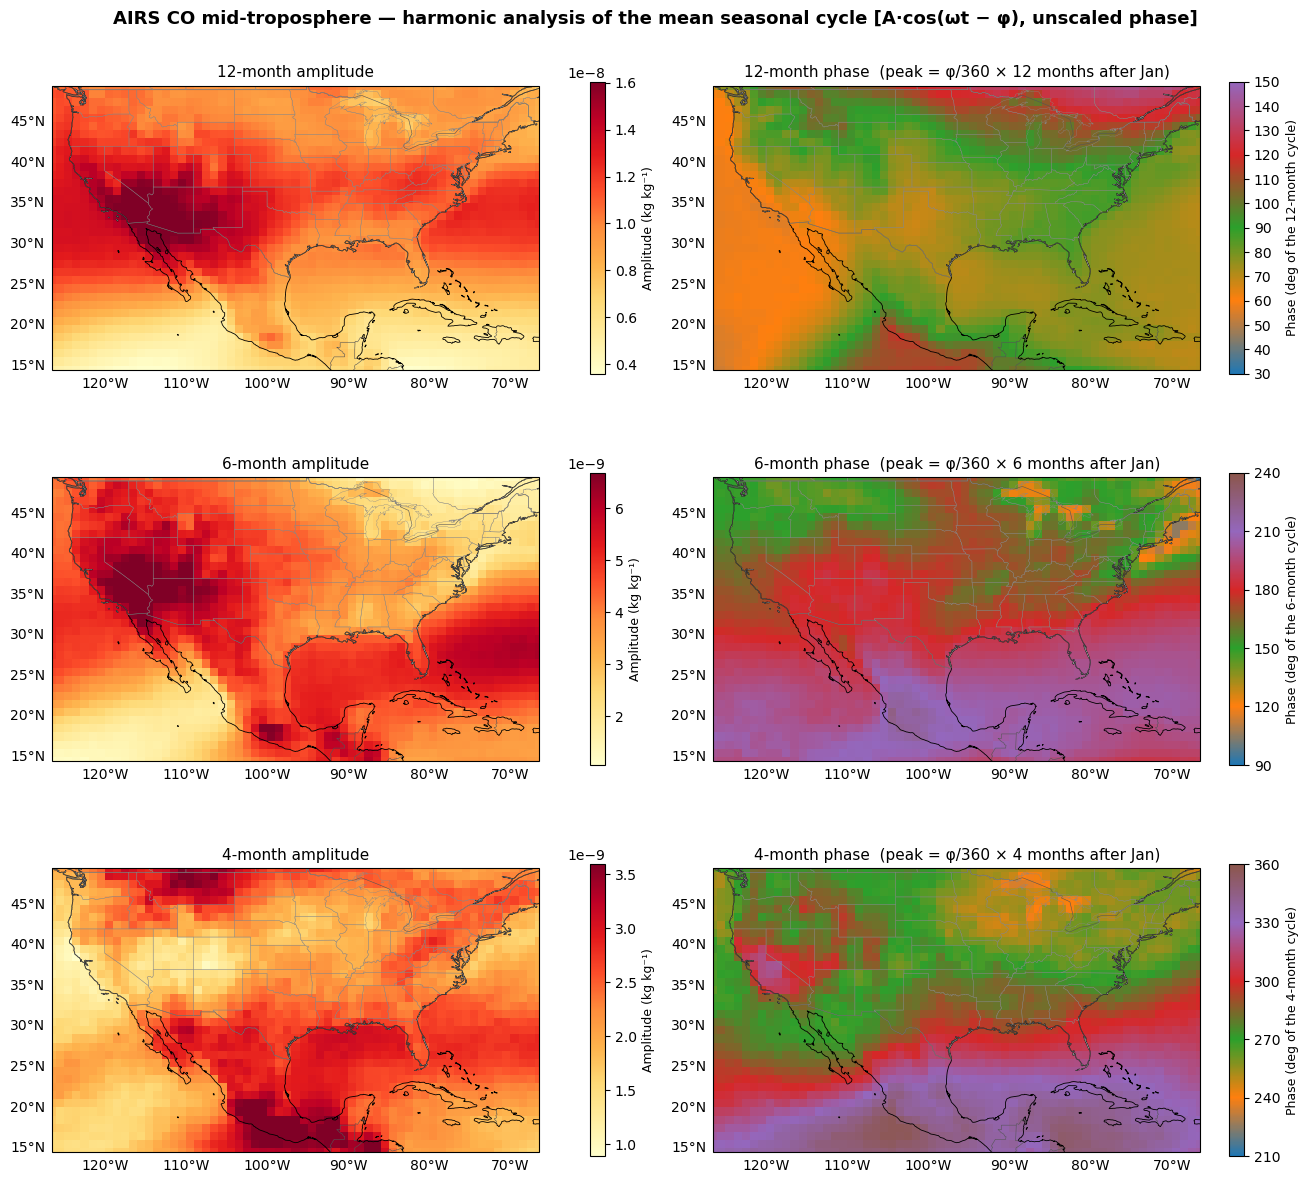

Saved -> ../../Figures/climatology/harmonic\harmonics_amp_phase_seasonal_cycle.png


In [5]:
ext = [float(lons.min()), float(lons.max()), float(lats.min()), float(lats.max())]

def harm_map(ax, data, cmap, label, title, norm=None, vmin=None, vmax=None, ticks=None):
    ax.set_extent(ext, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6, edgecolor="k")
    ax.add_feature(cfeature.BORDERS,   linewidth=0.4, edgecolor="#555")
    ax.add_feature(cfeature.STATES,    linewidth=0.25, edgecolor="#888")
    pcm = ax.pcolormesh(lons, lats, data, transform=ccrs.PlateCarree(),
                        cmap=cmap, norm=norm, vmin=vmin, vmax=vmax, shading="nearest")
    gl = ax.gridlines(draw_labels=True, linewidth=0, color="none")
    gl.top_labels = gl.right_labels = False
    cb = ax.figure.colorbar(pcm, ax=ax, orientation="vertical", fraction=0.03, pad=0.06, ticks=ticks)
    cb.set_label(label, fontsize=9)
    ax.set_title(title, fontsize=11, pad=6)
    return cb

# Distinct (qualitative) colors as keyframes every 30 degrees, cycled if a panel needs more
distinct_colors = plt.get_cmap("tab10").colors

fig_h, axes_h = plt.subplots(
    len(periods), 2, figsize=(13, 4 * len(periods)),
    subplot_kw={"projection": ccrs.PlateCarree()}, constrained_layout=True,
)
for r, P in enumerate(periods):
    ph = pha[P]                                   # unscaled degrees
    lo, hi = np.nanmin(ph), np.nanmax(ph)
    keyframes = np.arange(np.floor(lo / 30) * 30, np.ceil(hi / 30) * 30 + 30, 30)
    keyframe_colors = list(itertools.islice(itertools.cycle(distinct_colors), len(keyframes)))
    cmap_grad = mcolors.LinearSegmentedColormap.from_list(f"phase_grad_{P}", keyframe_colors, N=256)
    norm_grad = mcolors.Normalize(vmin=keyframes[0], vmax=keyframes[-1])
    step = 10 if keyframes[-1] - keyframes[0] <= 120 else 30
    ticks = np.arange(keyframes[0], keyframes[-1] + 1, step)

    harm_map(axes_h[r, 0], amp[P], "YlOrRd", "Amplitude (kg kg⁻¹)",
             f"{P}-month amplitude", vmax=np.nanpercentile(amp[P], 98))
    harm_map(axes_h[r, 1], ph, cmap_grad, f"Phase (deg of the {P}-month cycle)",
             f"{P}-month phase  (peak = φ/360 × {P} months after Jan)", norm=norm_grad, ticks=ticks)

fig_h.suptitle("AIRS CO mid-troposphere — harmonic analysis of the mean seasonal cycle [A·cos(ωt − φ), unscaled phase]",
               fontsize=13, fontweight="bold")
out_h = os.path.join(OUT_DIR, "harmonics_amp_phase_seasonal_cycle.png")
fig_h.savefig(out_h, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_h)

## Reference boxes: relative amplitude, relative phase and reconstruction

Box 1 (EOF 1 box) for the 12- and 6-month harmonics, box 3 (EOF 3 box) for the 4-month harmonic.

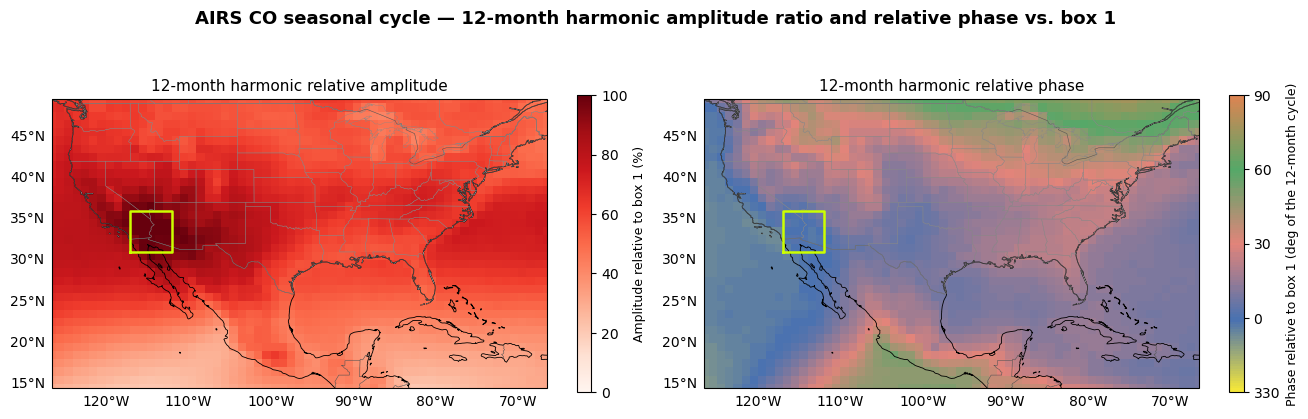

Box 1 coherence = 0.9991   amplitude ratio 21.2 - 106.3 %
Saved -> ../../Figures/climatology/harmonic\harmonic_12m_ampgain_relphase_box1.png


In [6]:
# --- reference boxes: amplitude ratio (x100) + relative phase vs. box, side by side ---
BOXES = {
    1: dict(LAT0=31, LAT1=36, LON0=-117, LON1=-112),   # EOF 1 box
    3: dict(LAT0=17, LAT1=19, LON0=-102, LON1=-99),    # EOF 3 box (used for the 4-month harmonic)
}
BOX = BOXES[1]

relphase_colors = [
    "#4b72b0", "#e2847a", "#55a868", "#dd8452", "#8172b3", "#ccb974",
    "#64b5cd", "#59a14f", "#b07aa1", "#8e44ad", "#c49a6c", "#ffee33",
]   # one colour per 30 deg (0, 30, ..., 330)

# doubled cyclic colormap over -360..360 so the colorbar can be centered on the 0/360 seam
phase_cmap  = mcolors.LinearSegmentedColormap.from_list("relphase", relphase_colors + relphase_colors[:1], N=360)
double_cmap = mcolors.ListedColormap([phase_cmap((v % 360) / 360) for v in np.linspace(-360, 360, 721)])
double_norm = mcolors.Normalize(vmin=-360, vmax=360)

def box_mean(da, box=1):
    b = BOXES[box]
    return da.sel(lat=slice(b["LAT0"], b["LAT1"]), lon=slice(b["LON0"], b["LON1"])).mean(("lat", "lon"))

def draw_box(ax, box=1):
    b = BOXES[box]
    ax.plot([b["LON0"], b["LON1"], b["LON1"], b["LON0"], b["LON0"]],
            [b["LAT0"], b["LAT0"], b["LAT1"], b["LAT1"], b["LAT0"]],
            "-", color="#ccff00", lw=1.8, transform=ccrs.PlateCarree())

def harm_recon(Ps):
    """Reconstructed field (month, lat, lon) from the harmonics with periods Ps (no annual mean)."""
    idx = [i for k, P in enumerate(periods) if P in Ps for i in (2*k, 2*k + 1)]
    return xr.DataArray((M[:, idx] @ coef[idx]).reshape(n_t, n_lat, n_lon),
                        dims=("month", "lat", "lon"),
                        coords={"month": months, "lat": lats, "lon": lons})

def plot_harm_ampgain_relphase(P, box=1):
    k = periods.index(P)
    z = xr.DataArray((coef[2*k] + 1j * coef[2*k + 1]).reshape(n_lat, n_lon),
                     dims=("lat", "lon"), coords={"lat": lats, "lon": lons})     # a + ib: |z| = A, angle = phi
    ref = box_mean(z, box)
    amp_gain  = 100 * np.abs(z.values) / np.abs(ref.values)                  # A(x) / |box ref|, %
    rel_phase = np.rad2deg(np.angle(z.values * np.conj(ref.values)))         # -180..180, 0 = box, > 0 peaks later

    b = BOXES[box]
    coherence = float(np.abs(ref) / np.abs(z.sel(lat=slice(b["LAT0"], b["LAT1"]),
                                                  lon=slice(b["LON0"], b["LON1"]))).mean())

    fig_hr, axes_hr = plt.subplots(
        1, 2, figsize=(13, 4.5),
        subplot_kw={"projection": ccrs.PlateCarree()}, constrained_layout=True,
    )
    harm_map(axes_hr[0], amp_gain, "Reds", f"Amplitude relative to box {box} (%)",
             f"{P}-month harmonic relative amplitude", vmin=0, vmax=100)          # clip at 100% (box)
    cb = harm_map(axes_hr[1], rel_phase, double_cmap, f"Phase relative to box {box} (deg of the {P}-month cycle)",
                  f"{P}-month harmonic relative phase", norm=double_norm)

    lo = np.floor(np.nanmin(rel_phase) / 30) * 30
    hi = np.ceil(np.nanmax(rel_phase) / 30) * 30
    cb.ax.set_ylim(lo, hi)
    ticks = np.arange(lo, hi + 1e-6, 30)
    cb.set_ticks(ticks)
    cb.set_ticklabels([f"{int(t % 360)}" for t in ticks])

    for ax in axes_hr:
        draw_box(ax, box)

    fig_hr.suptitle(f"AIRS CO seasonal cycle — {P}-month harmonic amplitude ratio and relative phase vs. box {box}",
                    fontsize=13, fontweight="bold")
    out_hr = os.path.join(OUT_DIR, f"harmonic_{P}m_ampgain_relphase_box{box}.png")
    fig_hr.savefig(out_hr, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Box {box} coherence = {coherence:.4f}   amplitude ratio {np.nanmin(amp_gain):.1f} - {np.nanmax(amp_gain):.1f} %")
    print("Saved ->", out_hr)

plot_harm_ampgain_relphase(12)

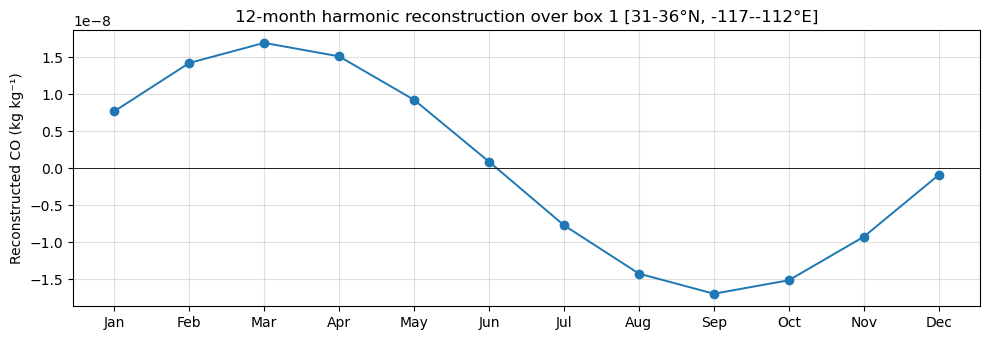

Saved -> ../../Figures/climatology/harmonic\harmonic_12m_recon_box1.png


In [7]:
# --- harmonic reconstruction over a reference box (box 1 by default) ---
def plot_harm_recon(Ps, box=1):
    ts = box_mean(harm_recon(Ps), box)
    name = " + ".join(f"{P}-month" for P in Ps)
    b = BOXES[box]

    fig_rc, ax_rc = plt.subplots(figsize=(10, 3.5))
    ax_rc.plot(mnames, ts.values, "o-", lw=1.4, color="#1f77b4")
    ax_rc.axhline(0, color="k", lw=0.6)
    ax_rc.set_title(f"{name} harmonic reconstruction over box {box} "
                    f"[{b['LAT0']}-{b['LAT1']}°N, {b['LON0']}-{b['LON1']}°E]")
    ax_rc.set_ylabel("Reconstructed CO (kg kg⁻¹)")
    ax_rc.grid(alpha=0.4)
    plt.tight_layout()
    out_rc = os.path.join(OUT_DIR, f"harmonic_{'_'.join(map(str, Ps))}m_recon_box{box}.png")
    fig_rc.savefig(out_rc, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved ->", out_rc)

plot_harm_recon([12])

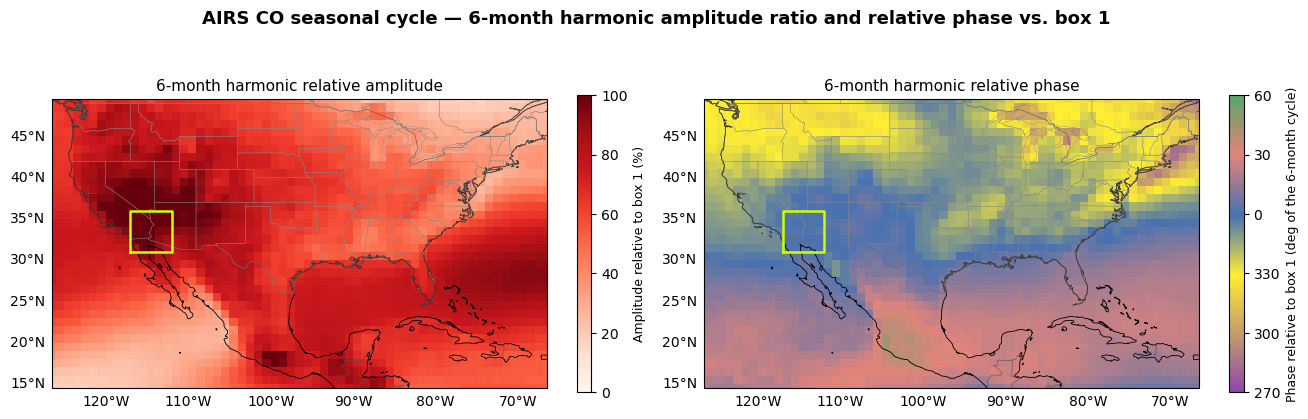

Box 1 coherence = 0.9997   amplitude ratio 16.0 - 113.3 %
Saved -> ../../Figures/climatology/harmonic\harmonic_6m_ampgain_relphase_box1.png


In [8]:
plot_harm_ampgain_relphase(6)

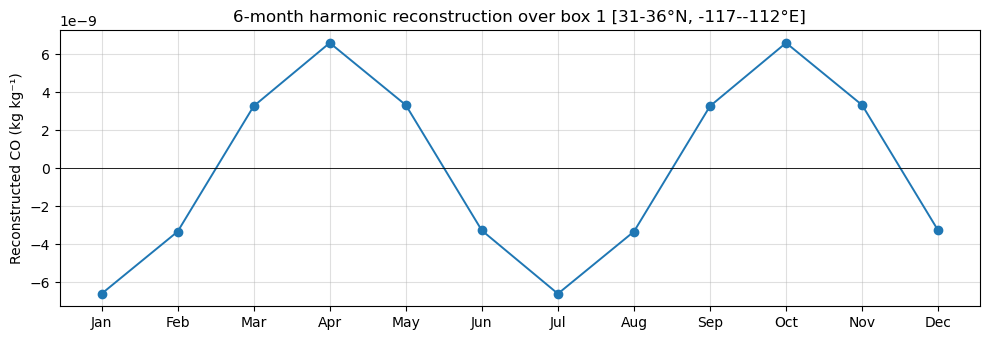

Saved -> ../../Figures/climatology/harmonic\harmonic_6m_recon_box1.png


In [9]:
plot_harm_recon([6])

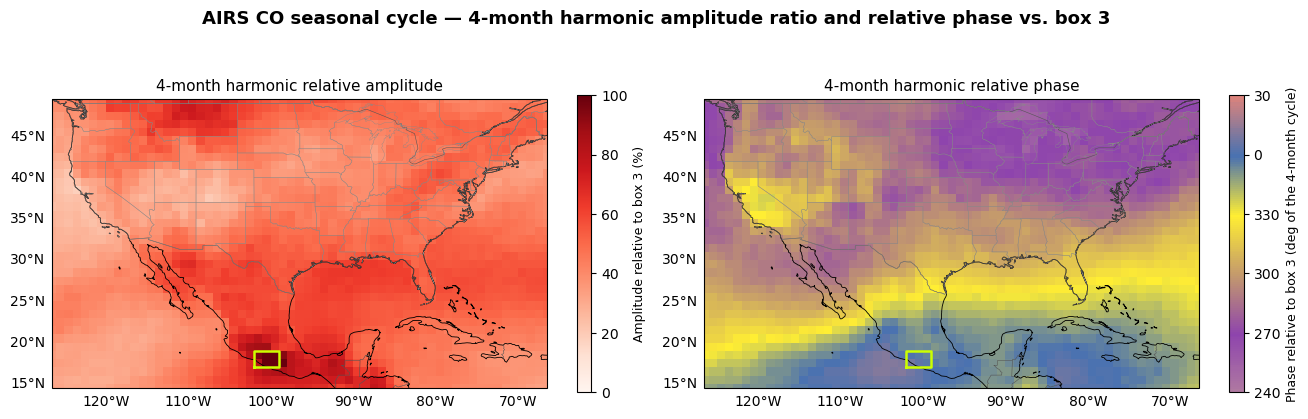

Box 3 coherence = 0.9971   amplitude ratio 18.3 - 113.7 %
Saved -> ../../Figures/climatology/harmonic\harmonic_4m_ampgain_relphase_box3.png


In [10]:
plot_harm_ampgain_relphase(4, box=3)

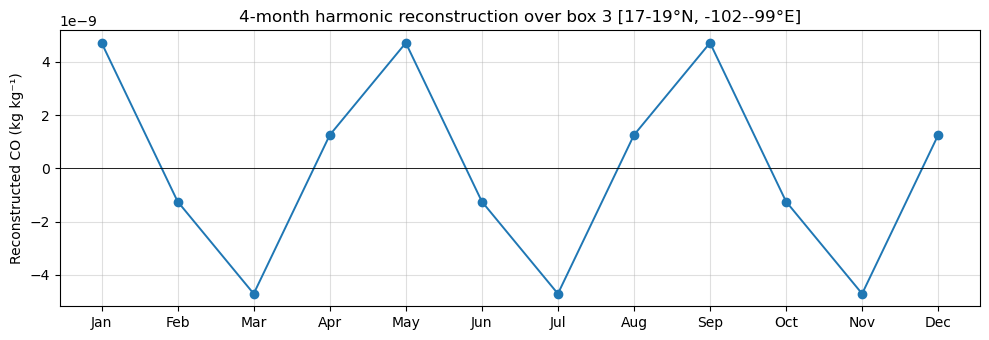

Saved -> ../../Figures/climatology/harmonic\harmonic_4m_recon_box3.png


In [11]:
plot_harm_recon([4], box=3)

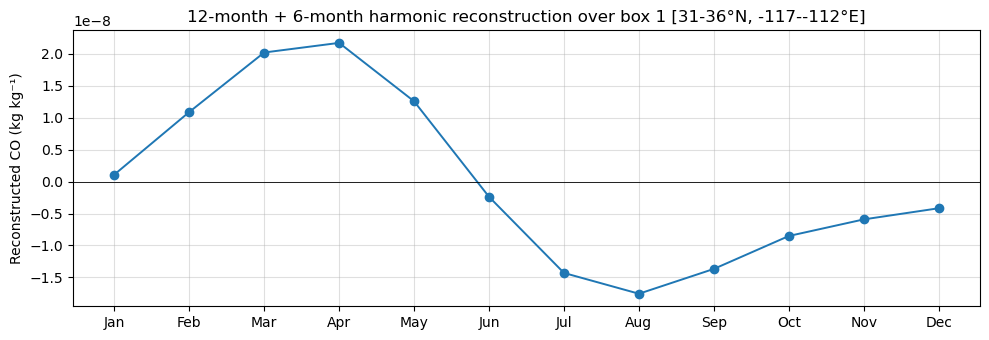

Saved -> ../../Figures/climatology/harmonic\harmonic_12_6m_recon_box1.png


In [12]:
plot_harm_recon([12, 6])

## Harmonic reconstruction & variance explained

In [14]:
# Reconstruct each harmonic separately and combined (deviations from the annual mean)
recon = {P: harm_recon([P]) for P in periods}
recon_total = harm_recon(periods)

# Variance explained, relative to the seasonal variance about each pixel's annual mean
anom = cycle - cycle.mean("month")
var_data = float(anom.var("month").sum())
print(f"Total seasonal variance : {var_data:.4e} (kg/kg)²·pixels\n")
cum = 0.0
for P in periods:
    frac = 100 * float(recon[P].var("month").sum()) / var_data
    cum += frac
    print(f"  {P:2d}-month harmonic : {frac:5.1f}%")
print(f"  Combined (all 3) : {cum:5.1f}%")
print(f"  Residual         : {100-cum:5.1f}%")

Total seasonal variance : 1.4528e-13 (kg/kg)²·pixels

  12-month harmonic :  80.7%
   6-month harmonic :  14.3%
   4-month harmonic :   4.2%
  Combined (all 3) :  99.2%
  Residual         :   0.8%


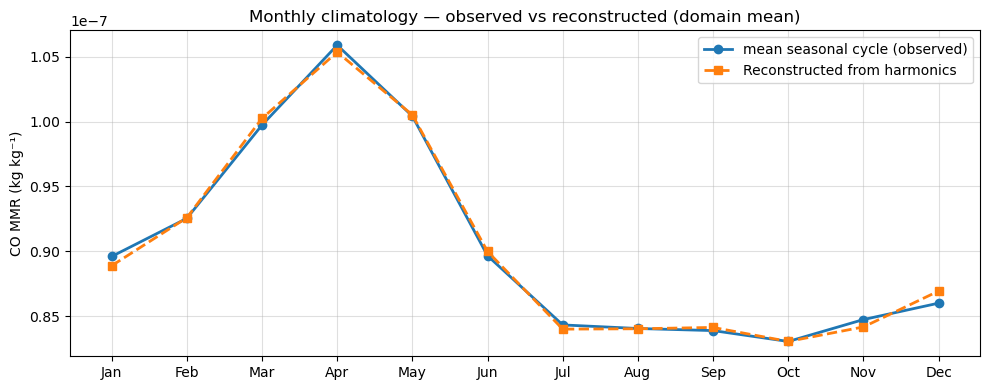

Saved -> ../../Figures/climatology/harmonic\domain_mean_cycle_vs_harmonic_recon.png


In [15]:
# Domain-mean seasonal cycle vs harmonic reconstruction
obs_clim   = cycle.mean(("lat", "lon")).values
recon_clim = (recon_total + annual_mean).mean(("lat", "lon")).values

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(mnames, obs_clim,   "o-", lw=2, label="mean seasonal cycle (observed)")
ax.plot(mnames, recon_clim, "s--", lw=2, label="Reconstructed from harmonics")
ax.set_ylabel("CO MMR (kg kg⁻¹)")
ax.set_title("Monthly climatology — observed vs reconstructed (domain mean)")
ax.legend(); ax.grid(alpha=0.4)
plt.tight_layout()
out = os.path.join(OUT_DIR, "domain_mean_cycle_vs_harmonic_recon.png")
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out)

In [16]:
# Comparison metrics on the seasonal deviations (all pixels and months flattened)
from scipy.stats import pearsonr

y     = anom.values.ravel()
y_hat = recon_total.values.ravel()
resid = y - y_hat

ss_res = np.sum(resid**2)
ss_tot = np.sum((y - y.mean())**2)
r2     = 1 - ss_res / ss_tot
rmse   = np.sqrt(np.mean(resid**2))
mae    = np.mean(np.abs(resid))
bias   = np.mean(resid)
r, _   = pearsonr(y, y_hat)

print("Comparison metrics (seasonal deviations, all pixels & months)")
print(f"  R²          : {r2:.4f}")
print(f"  Pearson r   : {r:.4f}")
print(f"  RMSE        : {rmse:.4e}  kg/kg")
print(f"  MAE         : {mae:.4e}  kg/kg")
print(f"  Bias (mean) : {bias:.4e}  kg/kg")

Comparison metrics (seasonal deviations, all pixels & months)
  R²          : 0.9917
  Pearson r   : 0.9958
  RMSE        : 7.4252e-10  kg/kg
  MAE         : 6.0210e-10  kg/kg
  Bias (mean) : -1.8884e-25  kg/kg


## Export reconstructed harmonic fields to NetCDF

Each harmonic's reconstructed seasonal field `A·cos(ωt − φ)` is written to its own file in
this folder, plus `periodicities.nc` with the sum of all three harmonics, the annual mean
and the residual.

In [17]:
harmonic_names = {12: "annual", 6: "semiannual", 4: "terannual"}
coords2d = {"lat": cycle.lat, "lon": cycle.lon}

for k, P in enumerate(periods):
    a_k = coef[2*k    ].reshape(n_lat, n_lon)
    b_k = coef[2*k + 1].reshape(n_lat, n_lon)

    da = recon[P].rename(f"harmonic_{P}m")
    da.attrs = {
        "long_name": f"{P}-month ({harmonic_names[P]}) harmonic of the AIRS CO mean seasonal cycle",
        "units": "kg/kg",
        "period_months": P,
        "description": "Reconstructed harmonic component A*cos(w*t - phi), "
                       "w = 2*pi/P, t = month - 1 (t = 0 in January)",
        "variance_explained_percent": 100 * float(recon[P].var("month").sum()) / var_data,
    }

    ds = xr.Dataset(
        {
            f"harmonic_{P}m": da,
            "amplitude": xr.DataArray(amp[P], dims=("lat", "lon"), coords=coords2d,
                                      attrs={"long_name": f"{P}-month harmonic amplitude", "units": "kg/kg"}),
            "phase": xr.DataArray(pha[P], dims=("lat", "lon"), coords=coords2d,
                                  attrs={"long_name": f"{P}-month harmonic phase (peak lag, unscaled)",
                                         "units": "degrees", "convention": "A*cos(w*t - phi), 0-360"}),
            "phase_months": xr.DataArray(pha[P] * (P / 360), dims=("lat", "lon"), coords=coords2d,
                                         attrs={"long_name": f"{P}-month harmonic peak, months after January",
                                                "units": "months"}),
            "a_cos": xr.DataArray(a_k, dims=("lat", "lon"), coords=coords2d,
                                  attrs={"long_name": "cosine regression coefficient", "units": "kg/kg"}),
            "b_sin": xr.DataArray(b_k, dims=("lat", "lon"), coords=coords2d,
                                  attrs={"long_name": "sine regression coefficient", "units": "kg/kg"}),
        },
        attrs={
            "title": f"{P}-month harmonic of the AIRS CO mid-troposphere mean seasonal cycle",
            "source": f"{IN_NC}, least-squares harmonic regression (12/6/4-month + constant)",
            "period_months": P,
        },
    )

    fname = f"harmonic_{P}m.nc"
    ds.to_netcdf(fname)
    print(f"Saved -> {fname}   vars: {list(ds.data_vars)}   shape: {da.shape}")

Saved -> harmonic_12m.nc   vars: ['harmonic_12m', 'amplitude', 'phase', 'phase_months', 'a_cos', 'b_sin']   shape: (12, 36, 61)
Saved -> harmonic_6m.nc   vars: ['harmonic_6m', 'amplitude', 'phase', 'phase_months', 'a_cos', 'b_sin']   shape: (12, 36, 61)
Saved -> harmonic_4m.nc   vars: ['harmonic_4m', 'amplitude', 'phase', 'phase_months', 'a_cos', 'b_sin']   shape: (12, 36, 61)


In [18]:
periodicities = recon_total.rename("periodicities")
periodicities.attrs = {
    "long_name": "Combined 12+6+4 month harmonic reconstruction of the AIRS CO mean seasonal cycle",
    "units": "kg/kg",
    "periods_months": "12, 6, 4",
    "description": "Sum of the annual, semi-annual and terannual harmonics, each A*cos(w*t - phi); "
                   "add annual_mean to get the reconstructed cycle",
}
annual_mean_da = xr.DataArray(annual_mean, dims=("lat", "lon"), coords=coords2d, name="annual_mean",
                              attrs={"long_name": "12-month mean of the seasonal cycle", "units": "kg/kg"})
residual = (cycle - annual_mean_da - recon_total).rename("residual")
residual.attrs = {"long_name": "seasonal cycle minus (annual mean + combined harmonics)", "units": "kg/kg"}

ds_all = xr.Dataset(
    {
        "periodicities": periodicities,
        "harmonic_12m": recon[12],
        "harmonic_6m":  recon[6],
        "harmonic_4m":  recon[4],
        "annual_mean":  annual_mean_da,
        "residual":     residual,
    },
    attrs={
        "title": "AIRS CO mid-troposphere — harmonic (periodic) signal of the mean seasonal cycle",
        "source": f"{IN_NC}, least-squares harmonic regression (12/6/4-month + constant)",
        "variance_explained_total_percent": 100 * float(recon_total.var("month").sum()) / var_data,
        "variance_explained_12m_percent": 100 * float(recon[12].var("month").sum()) / var_data,
        "variance_explained_6m_percent":  100 * float(recon[6].var("month").sum()) / var_data,
        "variance_explained_4m_percent":  100 * float(recon[4].var("month").sum()) / var_data,
    },
)
ds_all = ds_all.assign_coords(month_name=("month", mnames))
ds_all.to_netcdf("periodicities.nc")
print("Saved -> periodicities.nc")
print(ds_all)

Saved -> periodicities.nc
<xarray.Dataset> Size: 1MB
Dimensions:        (month: 12, lat: 36, lon: 61)
Coordinates:
  * month          (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * lat            (lat) float32 144B 14.5 15.5 16.5 17.5 ... 47.5 48.5 49.5
  * lon            (lon) float32 244B -126.5 -125.5 -124.5 ... -68.5 -67.5 -66.5
    month_name     (month) <U3 144B 'Jan' 'Feb' 'Mar' ... 'Oct' 'Nov' 'Dec'
Data variables:
    periodicities  (month, lat, lon) float64 211kB 3.195e-09 ... -5.661e-09
    harmonic_12m   (month, lat, lon) float64 211kB 2.96e-09 ... -5.954e-09
    harmonic_6m    (month, lat, lon) float64 211kB -1.126e-09 ... -1.709e-09
    harmonic_4m    (month, lat, lon) float64 211kB 1.361e-09 ... 2.002e-09
    annual_mean    (lat, lon) float64 18kB 8.161e-08 8.152e-08 ... 9.496e-08
    residual       (month, lat, lon) float64 211kB 6.939e-10 ... -7.191e-10
Attributes:
    title:                             AIRS CO mid-troposphere — harmonic (pe...
    source:           

In [19]:
# Verify: reopen the files and check the parts sum back to the whole
chk = xr.open_dataset("periodicities.nc")
parts = sum(xr.open_dataset(f"harmonic_{P}m.nc")[f"harmonic_{P}m"] for P in periods)

print("Max |sum(harmonic files) - periodicities| :",
      float(np.abs(parts - chk["periodicities"]).max()))
print("Max |annual_mean + periodicities + residual - cycle| :",
      float(np.abs(chk["annual_mean"] + chk["periodicities"] + chk["residual"] - cycle).max()))
for P in periods:
    d = xr.open_dataset(f"harmonic_{P}m.nc")
    print(f"harmonic_{P}m.nc  ->  {dict(d.sizes)}  vars: {list(d.data_vars)}")
    d.close()
chk.close()

Max |sum(harmonic files) - periodicities| : 6.617444900424222e-24
Max |annual_mean + periodicities + residual - cycle| : 1.3234889800848443e-23
harmonic_12m.nc  ->  {'month': 12, 'lat': 36, 'lon': 61}  vars: ['harmonic_12m', 'amplitude', 'phase', 'phase_months', 'a_cos', 'b_sin']
harmonic_6m.nc  ->  {'month': 12, 'lat': 36, 'lon': 61}  vars: ['harmonic_6m', 'amplitude', 'phase', 'phase_months', 'a_cos', 'b_sin']
harmonic_4m.nc  ->  {'month': 12, 'lat': 36, 'lon': 61}  vars: ['harmonic_4m', 'amplitude', 'phase', 'phase_months', 'a_cos', 'b_sin']
